#Pokémon Dataset EDA

#1.Dataset overview

###1.1.Dataset Title
Pokemon

###1.2.Source link
[Pokemon Dataset](https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-04-01/readme.md)

###1.3.Short Description
This dataset contains information about Pokémon including their physical charactarsitics, types and battle statistics.


###1.4.Why I selected this dataset


###1.5.Data Dictionary

![alt text](images/image.png)



#2. Problem Definition

##2.1.Main Questions
1. What are the most common Pokémon types?
2. How are Pokémon battle statistics distributed?
3. Which battle statistics show the most variability?
4. What relationships exist between Pokémon battle statistics?
5. Is there a relationship between Battle Stats and Base Experience?

##2.2.Expected Insights
I expect to discover how Pokémon types differ in their battle statistics, identify which types tend to have stronger abilities, and explore how individual Pokémon statistics relate to their overall strength and Base Experience.




##Importing libraries


In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

##Loading and Understanding Dataset







In [3]:
df = pd.read_csv("pokemon_df.csv")

df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 949 entries, 0 to 948
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               949 non-null    int64  
 1   pokemon          949 non-null    str    
 2   species_id       949 non-null    int64  
 3   height           949 non-null    float64
 4   weight           949 non-null    float64
 5   base_experience  949 non-null    int64  
 6   type_1           949 non-null    str    
 7   type_2           510 non-null    str    
 8   hp               949 non-null    int64  
 9   attack           949 non-null    int64  
 10  defense          949 non-null    int64  
 11  special_attack   949 non-null    int64  
 12  special_defense  949 non-null    int64  
 13  speed            949 non-null    int64  
 14  color_1          949 non-null    str    
 15  color_2          510 non-null    str    
 16  color_f          510 non-null    str    
 17  egg_group_1      949 non-nu

In [4]:
df.head()

,id,pokemon,species_id,height,weight,base_experience,type_1,type_2,hp,attack,...,special_defense,speed,color_1,color_2,color_f,egg_group_1,egg_group_2,url_icon,generation_id,url_image
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,...,65,45,#78C850,#A040A0,#81A763,monster,plant,//archives.bulbagarden.net/media/upload/7/7b/0...,1.0,https://raw.githubusercontent.com/HybridShivam...
1,2,ivysaur,2,1.0,13.0,142,grass,poison,60,62,...,80,60,#78C850,#A040A0,#81A763,monster,plant,//archives.bulbagarden.net/media/upload/a/a0/0...,1.0,https://raw.githubusercontent.com/HybridShivam...
2,3,venusaur,3,2.0,100.0,236,grass,poison,80,82,...,100,80,#78C850,#A040A0,#81A763,monster,plant,//archives.bulbagarden.net/media/upload/0/07/0...,1.0,https://raw.githubusercontent.com/HybridShivam...
3,4,charmander,4,0.6,8.5,62,fire,NaN,39,52,...,50,65,#F08030,NaN,NaN,monster,dragon,//archives.bulbagarden.net/media/upload/7/7d/0...,1.0,https://raw.githubusercontent.com/HybridShivam...
4,5,charmeleon,5,1.1,19.0,142,fire,NaN,58,64,...,65,80,#F08030,NaN,NaN,monster,dragon,//archives.bulbagarden.net/media/upload/b/be/0...,1.0,https://raw.githubusercontent.com/HybridShivam...


In [5]:
df.describe()

,id,species_id,height,weight,base_experience,hp,attack,defense,special_attack,special_defense,speed,generation_id
count,949.000000,949.000000,949.000000,949.000000,949.000000,949.000000,949.000000,949.000000,949.000000,949.000000,949.000000,802.000000
mean,1899.769231,400.133825,1.228240,66.213172,150.476291,68.954689,79.472076,74.066386,72.809273,72.217071,69.023182,3.694514
std,3507.954106,239.952021,1.267795,119.952240,76.391816,25.933562,31.946199,30.760762,32.632244,27.676920,29.209260,1.932751
min,1.000000,1.000000,0.100000,0.100000,36.000000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.000000
25%,238.000000,191.000000,0.500000,8.500000,68.000000,50.000000,55.000000,50.000000,50.000000,50.000000,45.000000,2.000000
50%,475.000000,395.000000,1.000000,28.800000,157.000000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,4.000000
75%,712.000000,615.000000,1.500000,66.600000,184.000000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.000000
max,10147.000000,802.000000,14.500000,999.900000,608.000000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,7.000000


##Cleaning Dataset


###Checking missing values and duplicates

In [6]:
df.duplicated().sum()
df["id"].duplicated().sum()

np.int64(0)

In [7]:
print((df.isnull().sum() / len(df)) * 100)

id                  0.000000
pokemon             0.000000
species_id          0.000000
height              0.000000
weight              0.000000
base_experience     0.000000
type_1              0.000000
type_2             46.259220
hp                  0.000000
attack              0.000000
defense             0.000000
special_attack      0.000000
special_defense     0.000000
speed               0.000000
color_1             0.000000
color_2            46.259220
color_f            46.259220
egg_group_1         0.000000
egg_group_2        74.920969
url_icon           24.025290
generation_id      15.489989
url_image           0.000000
dtype: float64


* Type_2 has 46.25% of missing values. It means that the pokemon is single type because there are dual type pokemons which have two distinct types. same with egg_group_2.

* For other columns like color_2 and url_icon they are unneccessary columns.

* The missing values in generation_id must be handled before proceeding with data analysis.


In [11]:
#From Pokemon website, I found that each range of species belongs to a specific generation. 
#The labels are the ranges of each generation while the bins are the generation ids. 
bins = [0, 151, 251, 386, 493, 649, 721, 809, 905, 1000]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9]

#Using pd.cut I filled the null values with its corresponding generation based on Pokemon id. 
df["generation_id"] = df["generation_id"].fillna(pd.cut(df["species_id"], bins=bins, labels=labels).astype(float)).astype(int)


#Checking null values
print(f"Number of missing values in generation_id: {df['generation_id'].isnull().sum()}")
print(f"Percentage of missing values in generation_id: {(df['generation_id'].isnull().sum() / len(df)) * 100}%")

#checking 
print(df[["species_id", "generation_id"]].tail())

Number of missing values in generation_id: 0
Percentage of missing values in generation_id: 0.0%
     species_id  generation_id
944         778              7
945         778              7
946         778              7
947         784              7
948         801              7


I discovered that generation_id is related to species_id, according to [Pokemon Wiki](https://pokemon.fandom.com/wiki/Generation#Generation_I). Therefore, species_id helped identify the missing generation values.
Each generation corresponds to a specific range of species ids.


In [24]:
from google.colab import files
df.to_csv("clean_pokemon.csv", index=False)
files.download("clean_pokemon.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Exploratory Data Analysis (EDA)

Each plot has a summary below it. 

<Axes: xlabel='type_1'>

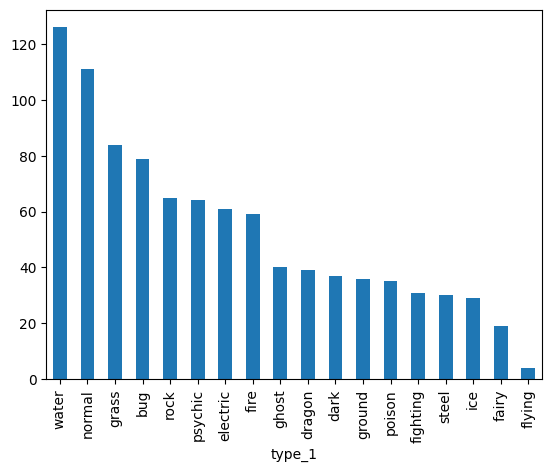

In [ ]:
#Calculating the number of pokemons for each primary type. 
df["type_1"].value_counts().plot(kind="bar")

The most common pokemon primary type is water while flying is the least common type as shown in figure.
The dataset is not balanced because some types appears more frequently than the others.

<Axes: xlabel='generation_id'>

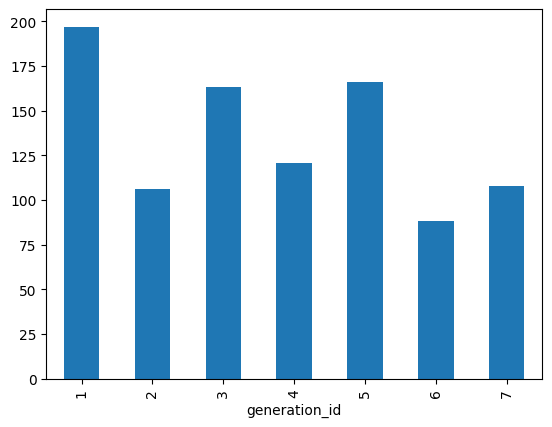

In [ ]:
#Calculating the number of pokemons for each primary type. 
df["generation_id"].value_counts().sort_index().plot(kind="bar")

The most frequent generation is the first generation while the least frequent generation is the sixth one.

Text(0.5, 0, 'HP')

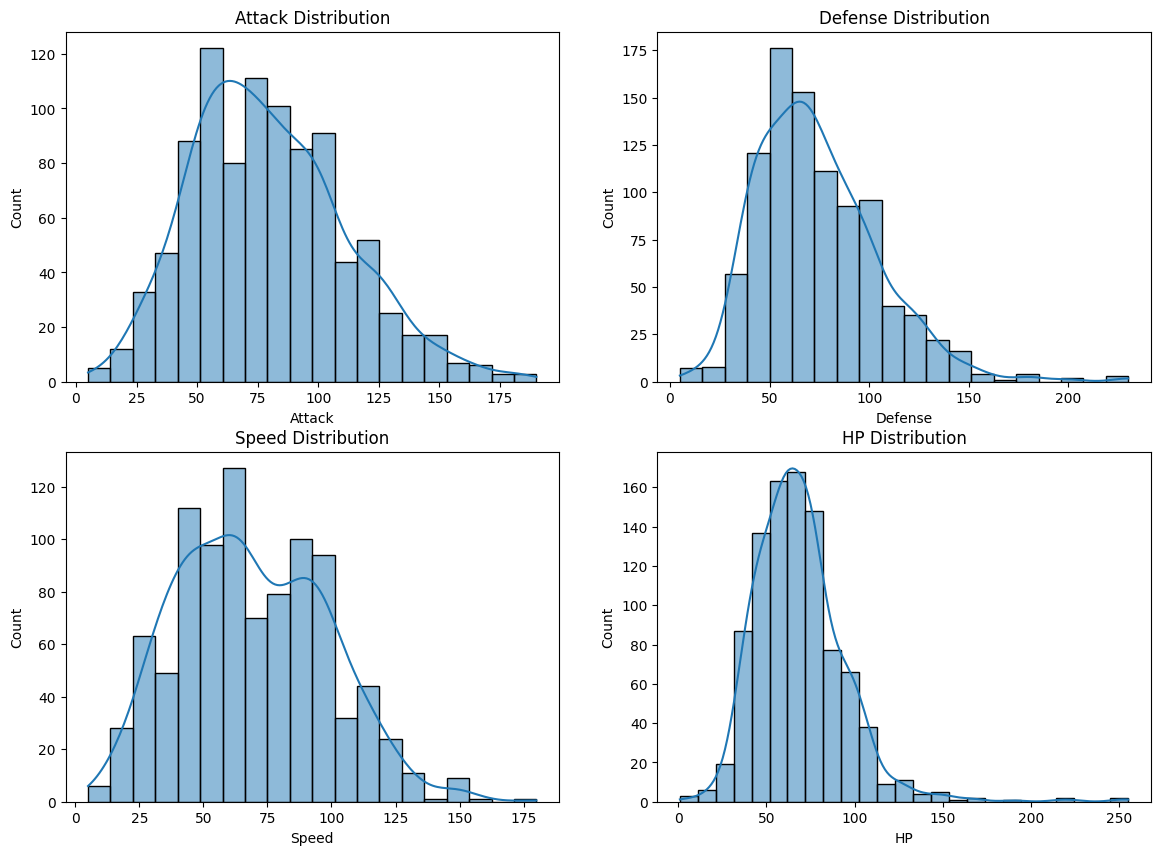

In [ ]:
plt.figure(figsize=(14,10))

#Histogram distribution of Attack
plt.subplot(2, 2, 1)
sns.histplot(df["attack"], kde=True, bins=20)
plt.title("Attack Distribution")
plt.xlabel("Attack")

#Histogram distribution of Defense
plt.subplot(2, 2, 2)
sns.histplot(df["defense"], kde=True, bins=20)
plt.title("Defense Distribution")
plt.xlabel("Defense")

#Histogram distribution of Speed
plt.subplot(2, 2, 3)
sns.histplot(df["speed"], kde=True, bins=20)
plt.title("Speed Distribution")
plt.xlabel("Speed")

#Histogram distribution of HP
plt.subplot(2, 2, 4)
sns.histplot(df["hp"], kde=True, bins=25)
plt.title("HP Distribution")
plt.xlabel("HP")

##Attack Distribution
Most pokemons have moderate attack values between 45-100. The distribution of attack is slightly skewed to the right which indicates that a small number of pokemons have high attack value.

##Defense Distribution
Most pokemons have 40-100 defense values. The distirbution of defense values is right skewed which indicates that a small number of pokemons have high defense values.

##Speed Distribution
As shown in figure, there is two peaks in Speed histogram around 50-60 and 90-100. This means there are two common speed ranges with small number of pokemons with high speed value.

##HP Distribution
Most pokemons have HP values between 50 and 80. The HP distribution is skewed to the right which indicates that a small number of pokemons have high HP value.

______________________________________________________________________________________________________________________________________________

<Axes: >

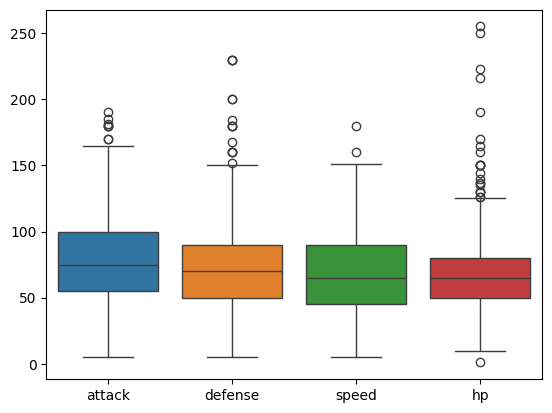

In [ ]:
#Boxplot of each Status 
sns.boxplot(df[["attack", "defense", "speed", "hp"]])

Attack and Speed show the greatest variablity while HP has a narrower distribution with many outliers. Defense falls between them with a few extreme values. These outliers may represent Pokemons with unusual high stats not data errors.

<Axes: xlabel='Primary Type'>

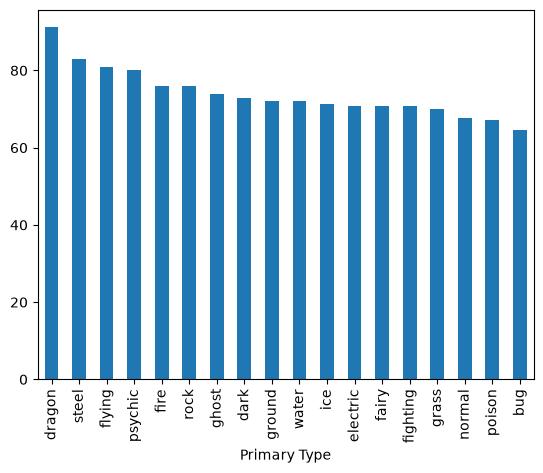

In [ ]:
#New column which contains the average of all the stats
stats = ["attack", "defense", "special_attack", "special_defense", "hp", "speed"]
df["avg_stat"] = df[stats].mean(axis=1)
df["avg_stat"].head()

#Bar chart of each primary type with the average stats
df.groupby("type_1")["avg_stat"].mean().sort_values(ascending=False).plot(kind="bar", xlabel="Primary Type")

Dragon Pokemon type has the highest average stats while Bug type has the lowest.This suggests that Dragon type pokemon tend to have higher overall stats compared with other types.

In [14]:
#Adding new column to indicate wether  Pokemon is Single or Dual Type

#if type_2 column is missing means that the Pokemon is Single type
df["type_cat"] = df["type_2"].isnull()
df["type_cat"].head()

#Mapping boolean values to categrical values (Single Type, Dual Type)
type_map={True: "Single Type", False:"Dual Type"}
df["type_cat"] = df["type_cat"].map(type_map)
df["type_cat"].head()

,type_cat
0,Dual Type
1,Dual Type
2,Dual Type
3,Single Type
4,Single Type


<Axes: xlabel='type_cat'>

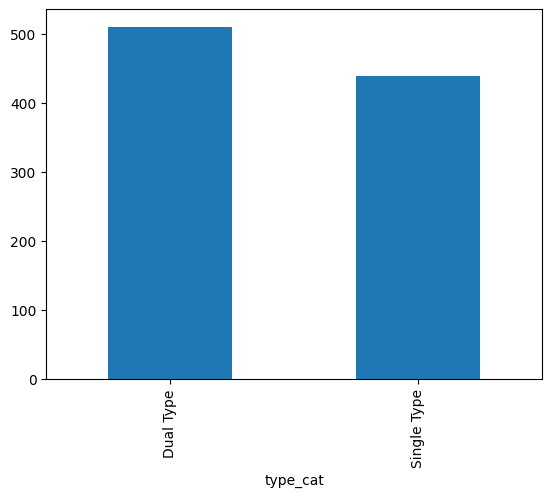

In [ ]:
#Bar chart of Type category count
df["type_cat"].value_counts().plot(kind="bar")

Dual Type Pokemon are slightly more common than single type pokemon. They are relatively close in size so the dataset is fairly balanced in terms of Type category.

<Axes: xlabel='type_cat'>

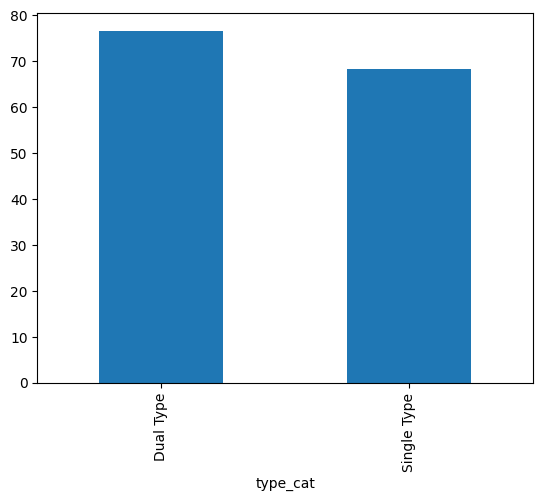

In [ ]:
##Bar chart of Type category average stats
df.groupby("type_cat")["avg_stat"].mean().plot(kind="bar")

Dual type Pokemon have a higher average battle stat tham Single type with a small difference. However, this does not mean that every Dual type Pokemon has higher stat than every Single type Pokemon.

<Axes: >

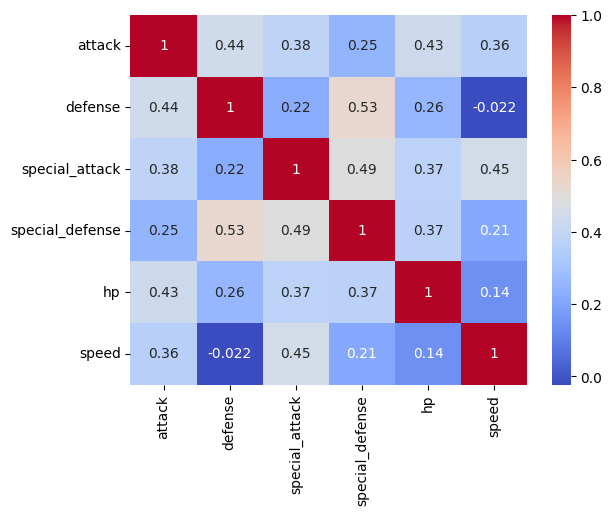

In [ ]:
#correlation matrix of all the stats
corr = df[stats].corr()
sns.heatmap(corr, annot = True, cmap="coolwarm")

The correlation matrix shows linear relationship between the stats:
* Defense and Special Defense have moderate positive relationship that means Pokemon with high defense tend to have high special defense but one does not neccesarily cause the other.(0.53)
* Special attack and special defense also show a moderate positive linear relationship.(0.49)
* Special attack and speed show a moderate positive relationship.(0.45)
* Speed and Defense show a moderate linear positive relationship.(0.44)
* Speed and Defense show almost no linear relationship as their correlation almost equal zero.


Text(0.5, 1.0, 'Defense vs Special Defense ')

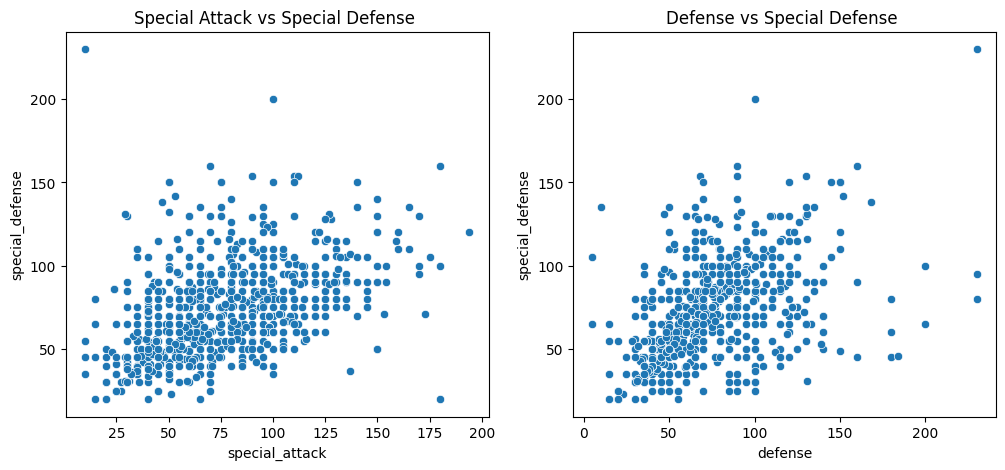

In [ ]:
plt.figure(figsize=(12, 5))

#plt.subplot(2, 2, 1)
#sns.scatterplot(x="special_attack" , y="speed", data=df)
#plt.title("Special Attack vs Speed ")

#Scatter plot between Special Attack and Special Defense
plt.subplot(1, 2, 1)
sns.scatterplot(x="special_attack" , y="special_defense", data=df)
plt.title("Special Attack vs Special Defense ")

#Scatter plot between Defense and Special Defense
plt.subplot(1, 2, 2)
sns.scatterplot(x="defense" , y="special_defense", data=df)
plt.title("Defense vs Special Defense ")

#plt.subplot(2, 2, 4)
#sns.scatterplot(x="speed" , y="defense", data=df)
#plt.title("Speed vs Defense ")

The scatter plots supports the heatmap:
* Defense and Special Defense have a moderate positive relationship.
* Special Attack and Special Defense have a moderate positive relationship.
A few outliers appear away from the main cluster.

_____________________________________________________________________________________________


<Axes: xlabel='base_experience', ylabel='Count'>

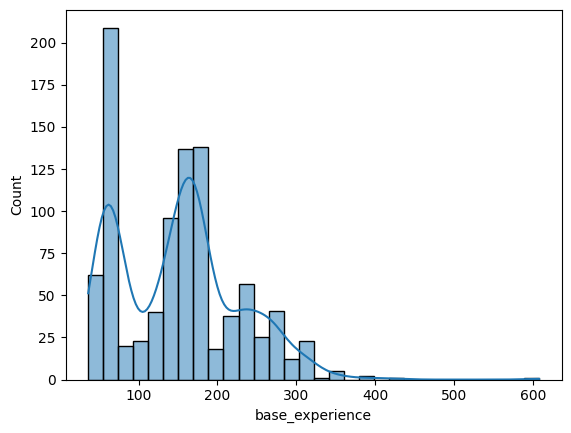

In [ ]:
#Histogram of Base Experience distribution
sns.histplot(df["base_experience"], bins=30, kde=True)

Most Pokemons base experience range between 35 and 60 and between 150 and 190. The distribution is right skewed with a few high outliers.

<Axes: xlabel='avg_stat', ylabel='base_experience'>

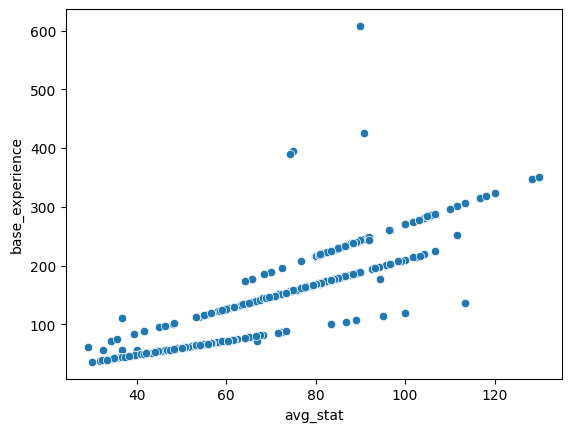

In [ ]:
#Scatter plot between Base Experience and Average Stats
sns.scatterplot(x="avg_stat", y="base_experience", data=df)

<Axes: >

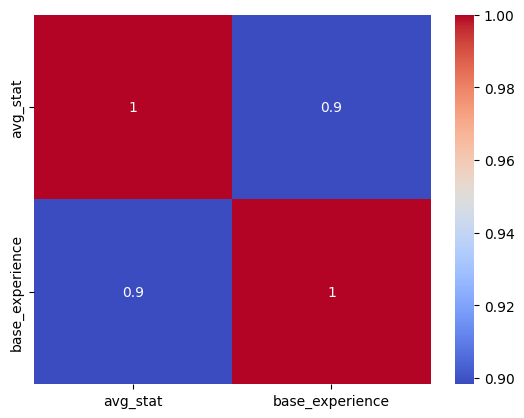

In [ ]:
#Correlation matrix of Average Stats with Base Experience 
sns.heatmap(df[["avg_stat", "base_experience"]].corr(), annot=True, cmap="coolwarm")

There is a strong positive correlation between Base Experience and Stats average with a three distinct diagonal patterns visible in the scatter plot.



<Axes: xlabel='exp_ratio', ylabel='Count'>

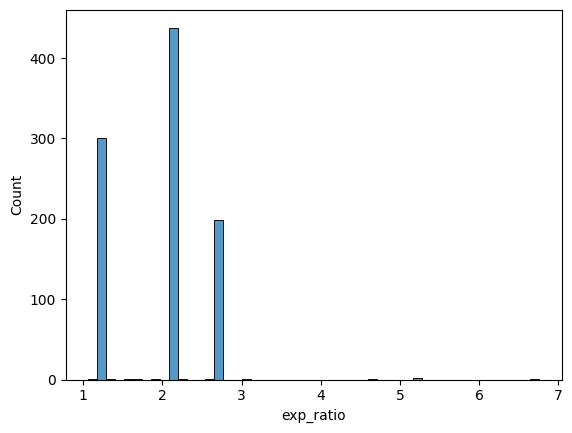

In [22]:
df["exp_ratio"] = df["base_experience"] / df["avg_stat"]
sns.histplot(df["exp_ratio"], bins=50)

<Axes: xlabel='avg_stat', ylabel='base_experience'>

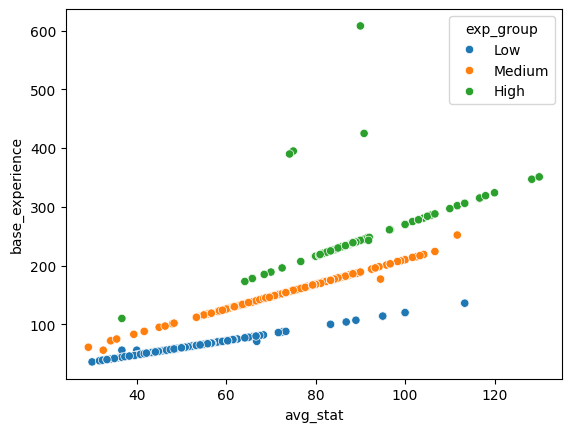

In [23]:
df["exp_group"] = pd.cut(df["exp_ratio"], bins=[0, 1.7, 2.4, 100], labels=["Low", "Medium", "High"])
sns.scatterplot(x="avg_stat", y="base_experience", hue="exp_group", data=df)

In [ ]:
#Define the features and The target 
feat = stats
X = df[stats]
Y = df["base_experience"]

#Splitting data into 80% training and 20% testing
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

#Training the model
model = LinearRegression()
model.fit(x_train, y_train)

#Model evaluation 
y_pred = model.predict(x_test)

print(f"R2: {r2_score(y_pred, y_test)}")
print(f"Mean squared error: {mean_squared_error(y_pred, y_test)}")

R2: 0.7087954415133879
Mean squared error: 1130.9479808208907
